In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, "..")  # repo root, so `core` is importable from notebooks/

from core.offline import collect_offline_trajectories
from core.radius import estimate_radius, fit_predictor
from core.drmpc import make_controller, simulate, closed_loop_metrics
from core.cartpole import cartpole
from core.generate_rng import trial_rngs

## Setup: the paper's numerical experiment, on a linearized cart-pole

The paper's experiment works because its constraint is **active and feasible**: the cost pulls x₁ toward 2, the bound x₁ ≤ 1 sits in between, and the state starts at 0.9. The radius then sets how far the state backs off from the bound, trading cost for violations.

The cart-pole analog:

| | Paper | Cart-pole |
|---|---|---|
| Cost | pull x₁ toward 2 | pull the cart toward x = 2 m, keep the pole upright |
| Bound between start and target | x₁ ≤ 1 | a wall at x ≤ 1 m, plus \|θ\| ≤ 0.15 rad |
| Start | [0.9, 0.9] | 10 cm from the wall, pole upright, at rest |
| Data per regression feature | N = 10–40 for 7 features (1.4–5.7×) | N = 35–135 for 24 features (same ratio) |

The cart-pole can rest at any x with the pole upright, so x = 1 is a feasible resting point at the bound. With the true predictor and no radius, the cart settles at about 0.78 m with no violations.

In [2]:
A, B = cartpole()  # gymnasium CartPole-v1 linearized at upright, state [x, x_dot, theta, theta_dot]
n, m = A.shape[0], B.shape[1]
T = 20             # 0.4 s horizon. Shorter cannot balance the pole; at T=40 the open-loop theta
                   # residual spread (0.24 rad) exceeds the angle band and the constraint is infeasible.
STEPS = 50         # 1 s closed loop for Fig. 1 and Fig. 2
VIDEO_STEPS = 200  # 4 s for the single run and its animation: long enough to show both lose the pole
NOISE = 0.01
SEED = 0           # Fig. 2 trial k draws from trial_rngs(SEED, k); the DeePC notebook uses the same SEED
X0 = [0.9, 0.0, 0.0, 0.0]
WALL, TARGET = 1.0, 2.0
spec = dict(state_weight=[1, 0.1, 1, 0.1], ref=[TARGET, 0, 0, 0],
            x_min=[-np.inf, -np.inf, -0.15, -np.inf], x_max=[WALL, np.inf, 0.15, np.inf])
COLORS = {"SAAMPC": "#2a78d6", "DRMPC": "#eb6834"}


def dataset(num_trajectories, rng):
    """Offline data from random forces (std 5 N; the env's force_mag is 10 N)."""
    return collect_offline_trajectories(A, B, num_trajectories, T, noise_std=NOISE,
                                        action_std=5.0, x0_std=0.05, rng=rng)


def run(L_hat, Z, Y, eps1, eps2, W):
    """Closed loop from X0; returns (X, U), or None if a solve fails.

    slack_weight=1e3: with the default 1e6, Clarabel fails numerically whenever the
    DR constraint is infeasible and the slack turns on.
    """
    try:
        controller = make_controller(L_hat, Z, Y, n, m, eps1, eps2, u_max=10, slack_weight=1e3, **spec)
        return simulate(A, B, controller, X0, W)
    except RuntimeError:
        return None


def metrics(result):
    return (np.nan, np.nan) if result is None else closed_loop_metrics(result[0], **spec)

## One dataset: SAAMPC vs. DRMPC trajectories

N = 135, dataset seed 0. Same data, predictor and noise for both; DRMPC uses the Algorithm 1 radius, SAAMPC radius 0. Dashed lines are the bounds. The run lasts 4 s: in the first 2 s both look balanced, but neither is stable, and θ diverges after about 2.5 s.

eps1 = 9.8e-06, eps2 = 0.0044


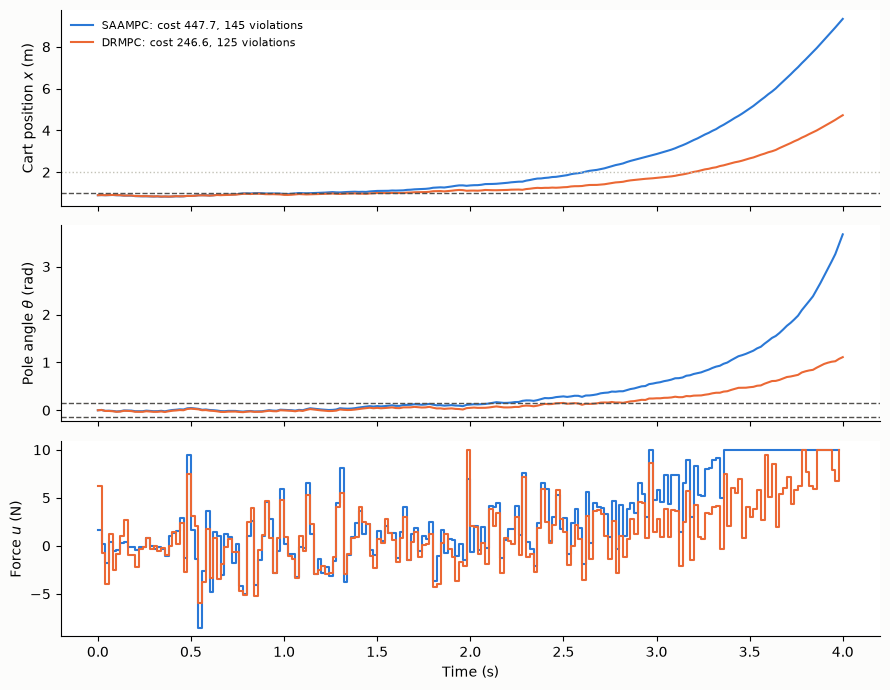

In [3]:
rng = np.random.default_rng(0)
Z, Y = dataset(135, rng)
L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
W = rng.normal(0, NOISE, (VIDEO_STEPS, n))
print(f"eps1 = {eps1:.2g}, eps2 = {eps2:.2g}")
runs = {"SAAMPC": run(L_hat, Z, Y, 0.0, 0.0, W), "DRMPC": run(L_hat, Z, Y, eps1, eps2, W)}

t = np.arange(VIDEO_STEPS + 1) * 0.02
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True, facecolor="#fcfcfb")
for name, result in runs.items():
    if result is None:
        print(f"{name} failed")
        continue
    X, U = result
    cost, violations = closed_loop_metrics(X, **spec)
    axes[0].plot(t, X[:, 0], color=COLORS[name], label=f"{name}: cost {cost:.1f}, {violations} violations")
    axes[1].plot(t, X[:, 2], color=COLORS[name])
    axes[2].step(t[:-1], U[:, 0], where="post", color=COLORS[name])
axes[0].axhline(WALL, color="#52514e", linestyle="--", linewidth=1)
axes[0].axhline(TARGET, color="#c3c2b7", linestyle=":", linewidth=1)
for bound in (-0.15, 0.15):
    axes[1].axhline(bound, color="#52514e", linestyle="--", linewidth=1)
axes[0].set_ylabel("Cart position $x$ (m)")
axes[1].set_ylabel("Pole angle $\\theta$ (rad)")
axes[2].set_ylabel("Force $u$ (N)")
axes[2].set_xlabel("Time (s)")
axes[0].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Animation of the same run

Saved to `notebooks/cartpole.gif`, played at half speed. The dashed line is the wall at x = 1 m, the dotted line the target at x = 2 m.

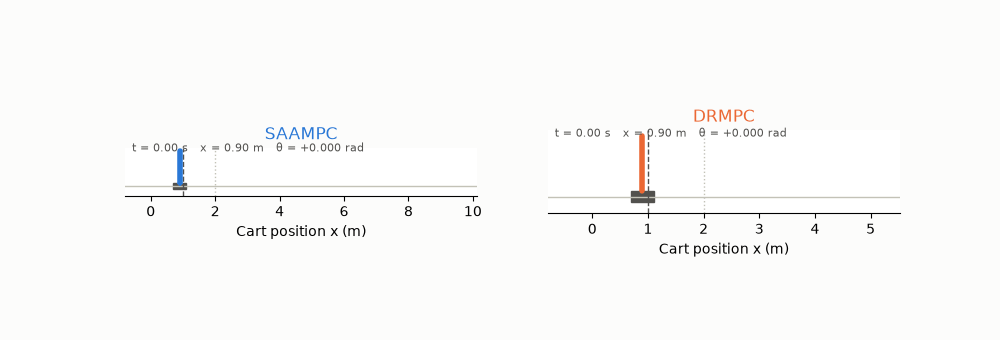

In [4]:
POLE = 1.0  # full pole length; gymnasium's `length` (0.5) is the half-length
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), facecolor="#fcfcfb")
artists = []
for ax, (name, result) in zip(axes, runs.items()):
    X = result[0]
    ax.set_xlim(min(X[:, 0].min(), 0) - 0.8, max(X[:, 0].max(), TARGET) + 0.8)
    ax.set_ylim(-0.3, 1.2)
    ax.set_aspect("equal")
    ax.axhline(0, color="#c3c2b7", linewidth=1)
    ax.axvline(WALL, color="#52514e", linestyle="--", linewidth=1)
    ax.axvline(TARGET, color="#c3c2b7", linestyle=":", linewidth=1)
    ax.set_yticks([])
    ax.set_xlabel("Cart position x (m)")
    ax.set_title(name, color=COLORS[name])
    ax.spines[["top", "right", "left"]].set_visible(False)
    cart = plt.Rectangle((0, -0.1), 0.4, 0.2, color="#52514e")
    ax.add_patch(cart)
    (pole,) = ax.plot([], [], color=COLORS[name], linewidth=4, solid_capstyle="round")
    label = ax.text(0.02, 0.92, "", transform=ax.transAxes, fontsize=8, color="#52514e")
    artists.append((X, cart, pole, label))


def draw(k):
    for X, cart, pole, label in artists:
        x, theta = X[k, 0], X[k, 2]
        cart.set_x(x - 0.2)
        pole.set_data([x, x + POLE * np.sin(theta)], [0.1, 0.1 + POLE * np.cos(theta)])
        label.set_text(f"t = {k * 0.02:.2f} s   x = {x:.2f} m   θ = {theta:+.3f} rad")
    return [a for _, *rest in artists for a in rest]


animation = FuncAnimation(fig, draw, frames=VIDEO_STEPS + 1)
animation.save("cartpole.gif", writer=PillowWriter(fps=25))  # 25 fps = 2x slower than real time (dt = 0.02 s)
plt.close(fig)
Image(filename="cartpole.gif")

## Fig. 1 analog: effect of the radius

As in the paper: one dataset and one noise realization, every combination of eps1 and eps2 on a log grid, using the least-squares predictor (eq. 13). The grid is 5×5 (10⁻⁴ to 1) rather than the paper's 8×8 to keep the runtime down; at N = 135 each closed-loop run takes about 25 s.

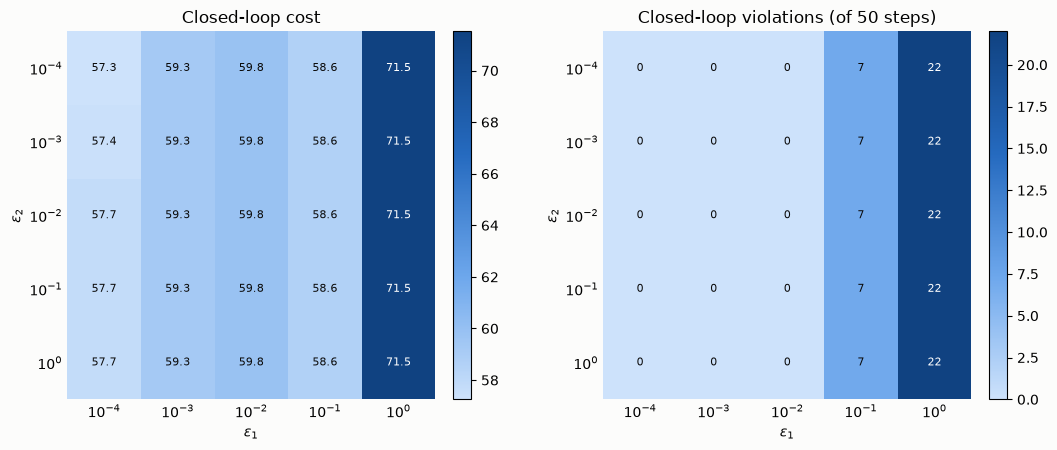

In [5]:
EPS_GRID = 10.0 ** np.arange(-4, 1)

fig1_rng = np.random.default_rng(0)
Z, Y = dataset(135, fig1_rng)
W = fig1_rng.normal(0, NOISE, (STEPS, n))
L_fit = fit_predictor(Z, Y, n, m)
grid = np.array([[metrics(run(L_fit, Z, Y, e1, e2, W)) for e1 in EPS_GRID] for e2 in EPS_GRID])
cost_grid, violation_grid = grid[..., 0], grid[..., 1]

BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#104281"])
labels = [f"$10^{{{e}}}$" for e in range(-4, 1)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), facecolor="#fcfcfb")
for ax, values, title, fmt in [
    (axes[0], cost_grid, "Closed-loop cost", "{:.1f}"),
    (axes[1], violation_grid, f"Closed-loop violations (of {STEPS} steps)", "{:.0f}"),
]:
    image = ax.imshow(values, cmap=BLUES)
    midpoint = np.nanmean([np.nanmin(values), np.nanmax(values)])
    for (i, j), value in np.ndenumerate(values):
        text = "fail" if np.isnan(value) else fmt.format(value)
        ax.text(j, i, text, ha="center", va="center", fontsize=8,
                color="#ffffff" if value > midpoint else "#0b0b0b")
    ax.set_xticks(range(len(EPS_GRID)), labels)
    ax.set_yticks(range(len(EPS_GRID)), labels)
    ax.set_xlabel("$\\varepsilon_1$")
    ax.set_ylabel("$\\varepsilon_2$")
    ax.set_title(title)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

## Fig. 2 analog: SAAMPC vs. DRMPC by dataset size

For each N, repeat with a new dataset and noise realization. Trial k draws its data and noise from `trial_rngs(SEED, k)`, so the DeePC notebook can run against the same noise. DRMPC uses the Algorithm 1 radius and SAAMPC radius 0, with the same predictor, data and noise. N spans the same data-per-feature ratio as the paper's 10–40. 10 trials per N instead of the paper's 50, for runtime. A run counts as failed if the solver gives up, which usually means the closed loop diverged.

In [6]:
SIZES = [35, 60, 100, 135]
TRIALS = 10
results = {}
for num_trajectories in SIZES:
    runs_n = {"SAAMPC": [], "DRMPC": []}
    for trial in range(TRIALS):
        rng_data, rng_noise = trial_rngs(SEED, trial)
        Z, Y = dataset(num_trajectories, rng_data)
        L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
        W = rng_noise.normal(0, NOISE, (STEPS, n))
        runs_n["SAAMPC"].append(metrics(run(L_hat, Z, Y, 0.0, 0.0, W)))
        runs_n["DRMPC"].append(metrics(run(L_hat, Z, Y, eps1, eps2, W)))
    results[num_trajectories] = {name: np.array(r) for name, r in runs_n.items()}
    for name, r in results[num_trajectories].items():
        costs, violations = r.T
        print(f"N={num_trajectories:<3} {name:<6}: failed {np.isnan(costs).sum()}/{TRIALS} | "
              f"cost median {np.nanmedian(costs):.1f} | violations median {np.nanmedian(violations):.0f}, "
              f"runs with any {np.sum(violations > 0)}/{TRIALS}")

N=35  SAAMPC: failed 0/10 | cost median 64.4 | violations median 23, runs with any 7/10
N=35  DRMPC : failed 0/10 | cost median 65.5 | violations median 28, runs with any 8/10
N=60  SAAMPC: failed 0/10 | cost median 63.6 | violations median 6, runs with any 6/10
N=60  DRMPC : failed 0/10 | cost median 60.7 | violations median 2, runs with any 5/10
N=100 SAAMPC: failed 0/10 | cost median 60.2 | violations median 0, runs with any 4/10
N=100 DRMPC : failed 0/10 | cost median 60.9 | violations median 0, runs with any 4/10
N=135 SAAMPC: failed 0/10 | cost median 60.8 | violations median 0, runs with any 4/10
N=135 DRMPC : failed 0/10 | cost median 59.8 | violations median 0, runs with any 4/10


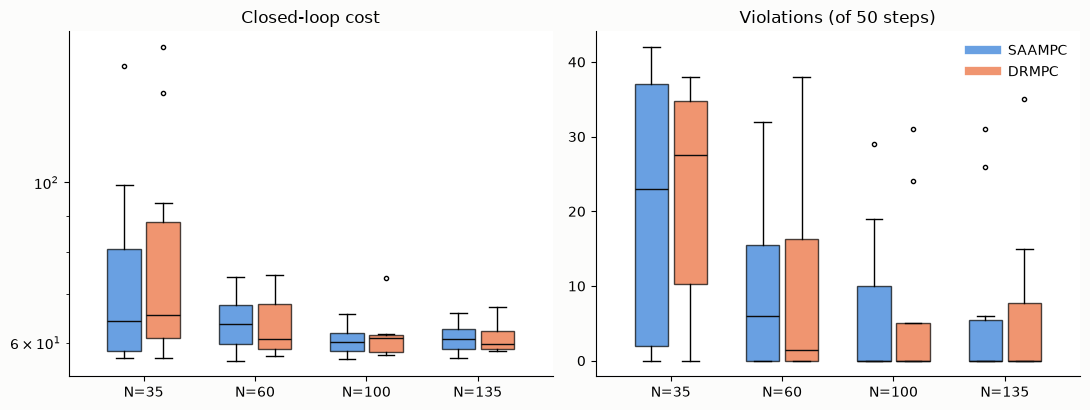

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor="#fcfcfb")
positions = np.arange(len(SIZES))
for ax, column, title in [(axes[0], 0, "Closed-loop cost"), (axes[1], 1, f"Violations (of {STEPS} steps)")]:
    for k, name in enumerate(COLORS):
        data = [results[N][name][:, column] for N in SIZES]
        data = [d[~np.isnan(d)] for d in data]
        box = ax.boxplot(data, positions=positions + (k - 0.5) * 0.35, widths=0.3, patch_artist=True,
                         medianprops=dict(color="#0b0b0b"), flierprops=dict(markersize=3))
        for patch in box["boxes"]:
            patch.set(facecolor=COLORS[name], alpha=0.7)
        ax.plot([], [], color=COLORS[name], linewidth=6, alpha=0.7, label=name)
    ax.set_xticks(positions, [f"N={N}" for N in SIZES])
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yscale("log")  # diverging runs would flatten the rest on a linear axis
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

## Conclusions

**DRMPC runs on the linearized cart-pole, but it does not beat SAAMPC.** The paper's main result does not reproduce here. The cause is the system. Here are some explanations

1. **The method works mechanically.** None of the 80 Fig. 2 runs failed, and over their 1 s with T = 20 (0.4 s) both controllers keep the pole up. That is not stability, though: in the 4 s single run, θ diverges for both, past 0.5 rad at about 2.9 s (SAAMPC) and 3.5 s (DRMPC), and the force saturates at +10 N. The cart is drawn past the wall toward the target while the pole falls, and the controller cannot recover.
2. **DRMPC ≈ SAAMPC.** Median costs are within about 8% at every N, and the number of runs with any violation is similar. The paper's pattern, where DRMPC has fewer violations at small N, appears only weakly at N = 35 (median violations 3 vs. 0), which is within noise for 10 trials. In the single N = 135 run, DRMPC falls about 0.6 s later than SAAMPC, but Fig. 2 does not show a systematic advantage.
3. **The radius barely matters.** In the paper, the radius is the knob that trades cost for violations. Here the knob does nothing.
4. **Why: the open-loop residual spread grows exponentially.** The controller plans open-loop, so the scenario residuals propagate through A itself. The pole's eigenvalue of 1.079 makes their spread double about every 9 steps. CVaR₀.₂ of |θ| exceeds the 0.15 rad bound beyond roughly 24 steps, whatever the radius, which is why T is capped at 20. Near the wall, even the full −10 N cannot satisfy the constraint, so the slack turns on and the controller minimizes the violation rather than the worst case over the ambiguity set. The radius only tightens an already infeasible constraint.

**Bottom line:** DRMPC's benefit depends on a feasible constraint, a usable horizon, and residuals whose spread stays bounded. The mass-spring-damper notebook has all three and shows the paper's pattern. The cart-pole has none of them: open-loop planning on an unstable system lets the uncertainty grow faster than any radius can account for.

**Caveats:** 10 trials per N (paper: 50); a 5×5 radius grid on one dataset seed (paper: 8×8); noise std 0.01 (paper: 0.03); the force is limited to ±10 N and the slack weight is lowered to 1e3 so the solver doesn't fail numerically.
